In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
SEED = 37

In [2]:
# Load the entire portfolio dataset
data = pd.read_csv("HW5Portfolio25.csv")

# Convert the dates column to date format instead of ints
dates = pd.to_datetime(data["Date"], format="%Y%m%d")
X = data.drop(columns="Date").apply(pd.to_numeric, errors="coerce")

In [3]:
valid_X = X.notna().all(axis=1)
X = X.loc[valid_X]
dates = dates.loc[valid_X]

In [4]:
pca_all = PCA().fit(X)
explained = pca_all.explained_variance_ratio_
cumulative = np.cumsum(explained)

In [5]:
n_components = np.argmax(cumulative >= 0.90) + 1
print(f"Principal components for at least 90% variance: {n_components}")

Principal components for at least 90% variance: 6


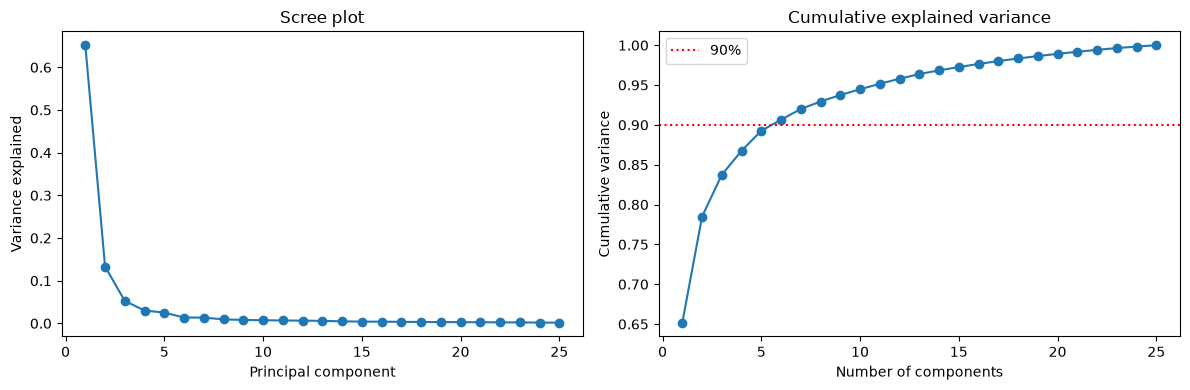

In [6]:
components = np.arange(1, len(explained) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(components, explained, marker="o")
axes[0].set(title="Scree plot", xlabel="Principal component", ylabel="Variance explained")
axes[1].plot(components, cumulative, marker="o")
axes[1].axhline(0.90, color="red", linestyle=":", label="90%")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components", ylabel="Cumulative variance")
axes[1].legend()
plt.tight_layout(); plt.show()

In [7]:
pca = PCA(n_components=n_components)
scores = pca.fit_transform(X)

pc_names = [f"PC{i}" for i in range(1, n_components + 1)]
scores_df = pd.DataFrame(scores, columns=pc_names, index=dates)
display(scores_df.head(20))

,PC1,PC2,PC3,PC4,PC5,PC6
Date,,,,,,
1926-07-01,0.147804,-0.500030,0.740417,0.203009,0.323630,0.928243
1926-07-02,0.640377,0.210350,-0.631616,1.456718,1.295260,-1.536060
1926-07-06,0.488396,0.185949,-0.479472,-0.453191,0.154566,-0.713260
1926-07-07,-0.425375,-0.894778,-1.255452,-0.179676,-0.105771,1.555379
1926-07-08,0.503189,0.265711,-0.925185,0.543001,0.998305,-0.914831
1926-07-09,-1.645876,1.902472,0.788244,-1.062659,-1.667565,0.389809
1926-07-10,1.220742,-0.434880,-1.427067,-0.784138,0.433714,-0.144875
1926-07-12,0.589481,0.210954,0.323421,-0.030299,-0.911247,-0.023185
1926-07-13,0.910687,-0.690586,0.699492,0.712619,0.935837,-0.746132


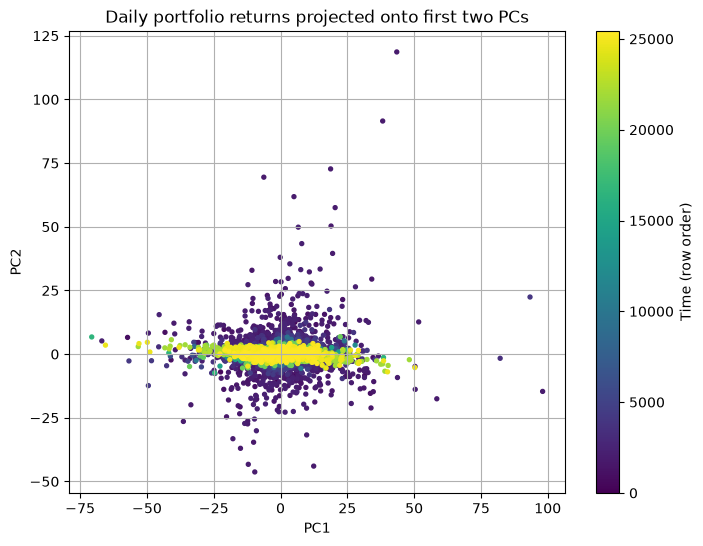

In [8]:
plt.figure(figsize=(8, 6))
points = plt.scatter(scores_df["PC1"], scores_df["PC2"], c=np.arange(len(scores_df)), s=8, cmap="viridis")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Daily portfolio returns projected onto first two PCs")
plt.colorbar(points, label="Time (row order)")
plt.grid(True)
plt.show()

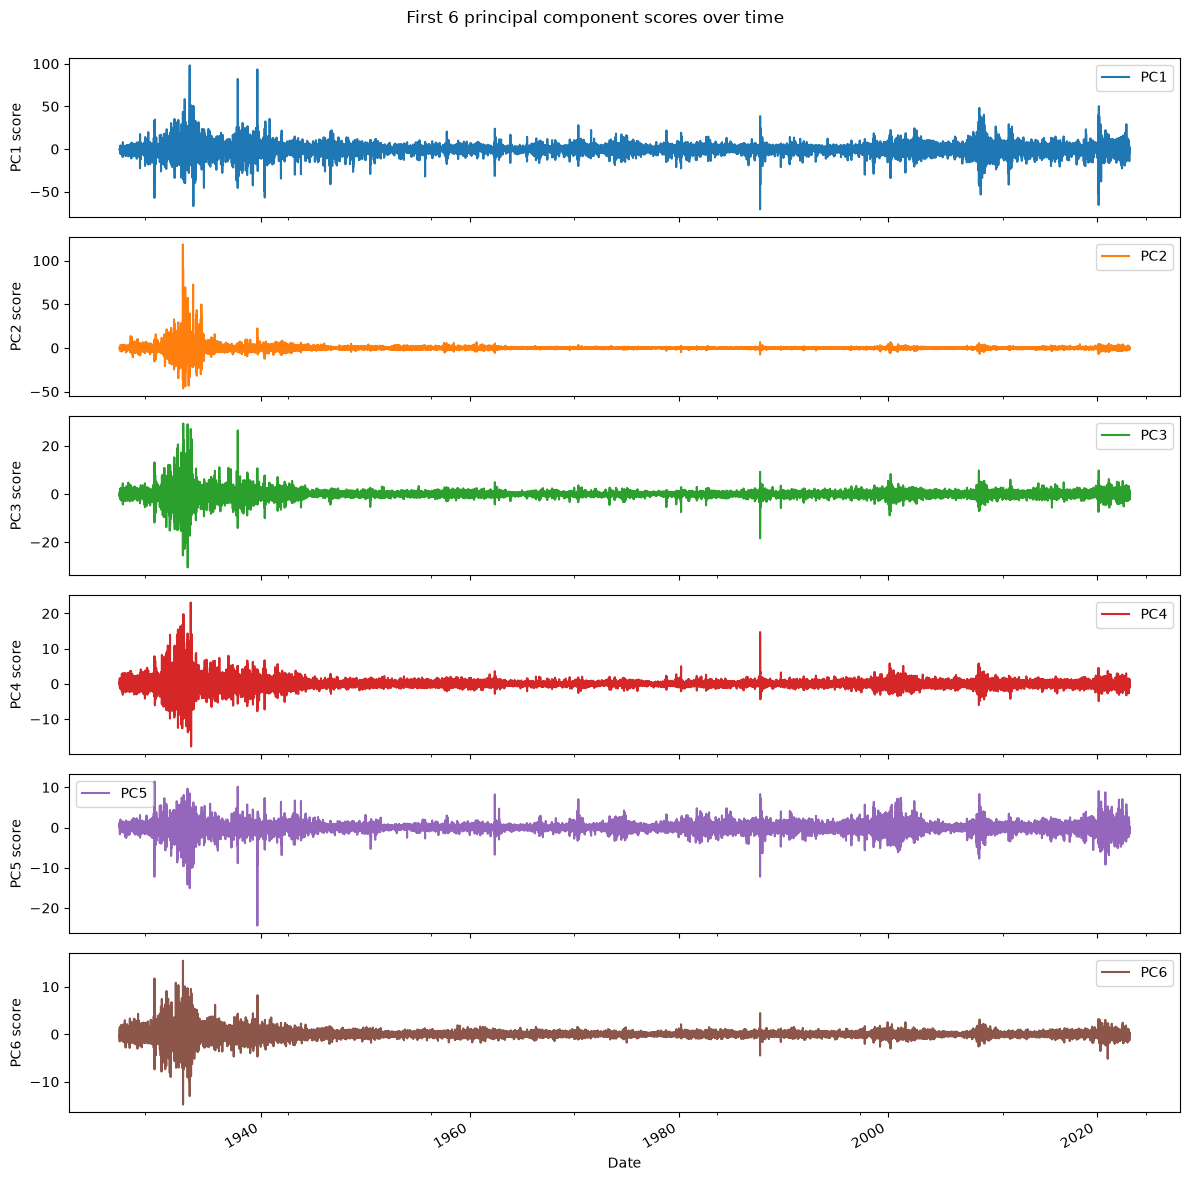

In [9]:
pcs = ["PC1", "PC2", "PC3", "PC4", "PC5", "PC6"]
axes = scores_df[pcs].plot(subplots=True, figsize=(12, 12), sharex=True)
for ax, pc in zip(axes, pcs):
    ax.set_ylabel(f"{pc} score")

axes[-1].set_xlabel("Date")
fig = axes[0].figure
fig.suptitle("First 6 principal component scores over time")
plt.tight_layout(rect=[0, 0, 1, 0.98]); plt.show()

### (b) Hierarchical Clustering Analysis on PCA Results


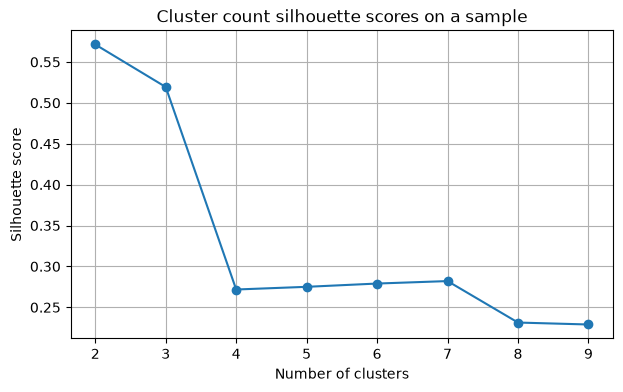

Best silhouette score in this range: k=2


In [10]:
# Use the chosen PC scores only, keep dates as the index not a feature
pc_cols = [f"PC{i}" for i in range(1, n_components + 1)]
pc_scores = scores_df[pc_cols]

# Reproducible sample for comparing clusters and drawing the dendrogram
sample = pc_scores.sample(n=5000, random_state=SEED)

# Compare silhouette scores for different cluster counts
k_vals = range(2, 10)
silhouette_scores = []
inertia = []
for k in k_vals:
    labels = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(sample)
    silhouette_scores.append(silhouette_score(sample, labels)) 

plt.figure(figsize=(7, 4))
plt.plot(list(k_vals), silhouette_scores, marker="o")
plt.xlabel("Number of clusters"); plt.ylabel("Silhouette score")
plt.title("Cluster count silhouette scores on a sample")
plt.grid(True); plt.show()

best_k = list(k_vals)[np.argmax(silhouette_scores)]
print(f"Best silhouette score in this range: k={best_k}")

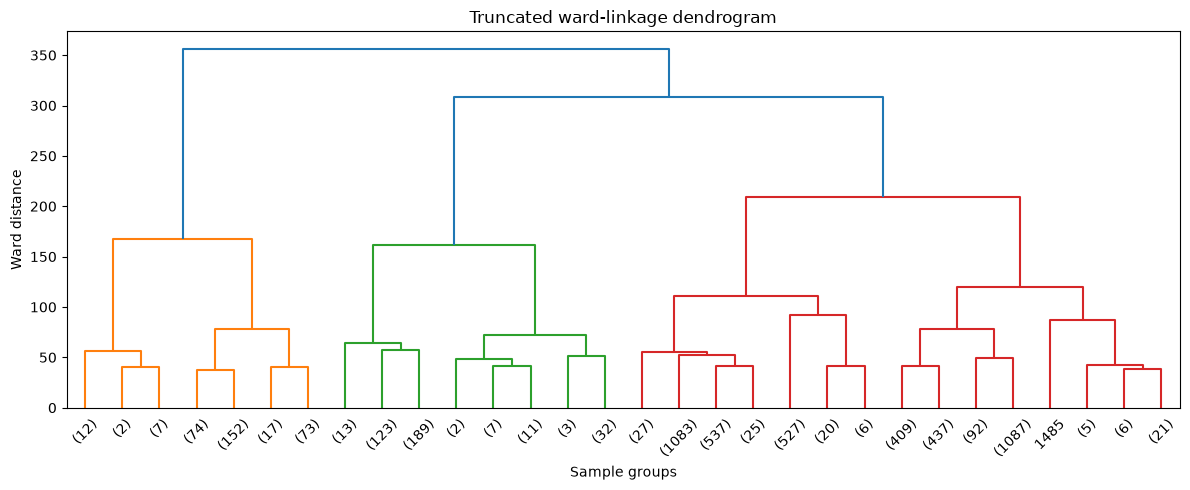

In [11]:
Z = linkage(sample.to_numpy(), method="ward", metric="euclidean")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.xlabel("Sample groups")
plt.ylabel("Ward distance")
plt.title("Truncated ward-linkage dendrogram")
plt.tight_layout(); plt.show()

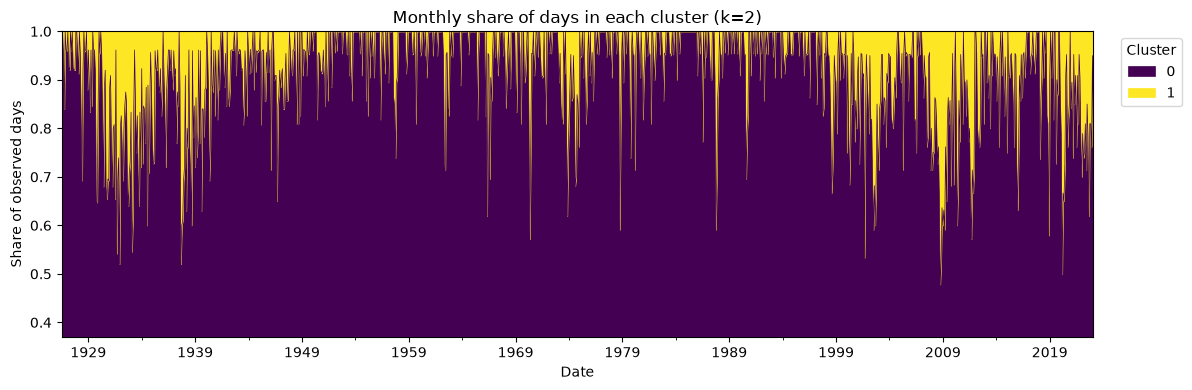

In [12]:
final_clustering = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
all_labels = final_clustering.fit_predict(pc_scores)

clustered = pc_scores.assign(cluster=all_labels)
monthly_share = pd.crosstab(clustered.index.to_period("M"), clustered["cluster"],
                             normalize="index").reindex(columns=range(best_k), fill_value=0)

monthly_share.index = monthly_share.index.to_timestamp()
ax = monthly_share.plot.area(figsize=(12, 4), colormap="viridis", linewidth=0.5)
ax.set(title=f"Monthly share of days in each cluster (k={best_k})", xlabel="Date", ylabel="Share of observed days", ylim=(0.37, 1))
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

### (c) K-Means Clustering Analysis


In [13]:
sample = pc_scores.sample(n=5000, random_state=SEED)

k_vals = list(range(2, 11))
inertias = []
silhouette_scores = []

for k in range(1, 11):
    candidate = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    sample_labels = candidate.fit_predict(sample)
    inertias.append(candidate.inertia_)
    if k >= 2:
        silhouette_scores.append(silhouette_score(sample, sample_labels))

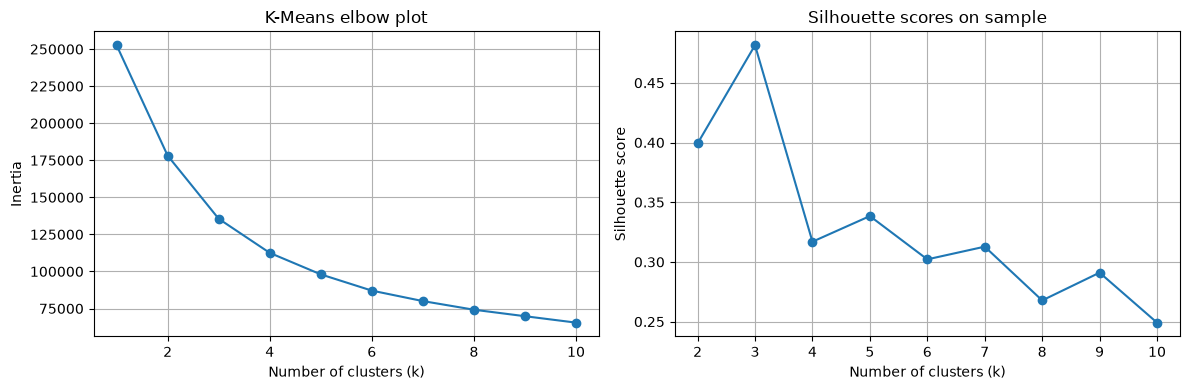

Highest silhouette score in this range: k=3


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, 11), inertias, marker="o")
axes[0].set(title="K-Means elbow plot", xlabel="Number of clusters (k)", ylabel="Inertia")
axes[0].grid(True)

axes[1].plot(k_vals, silhouette_scores, marker="o")
axes[1].set(title="Silhouette scores on sample", xlabel="Number of clusters (k)", ylabel="Silhouette score")
axes[1].grid(True)
plt.tight_layout(); plt.show()

suggested_k = k_vals[np.argmax(silhouette_scores)]
print(f"Highest silhouette score in this range: k={suggested_k}")

In [15]:
chosen_k = suggested_k

kmeans = KMeans(n_clusters=chosen_k, n_init=20, random_state=SEED)
labels = kmeans.fit_predict(pc_scores)

clustered_kmeans = pc_scores.assign(cluster=labels)

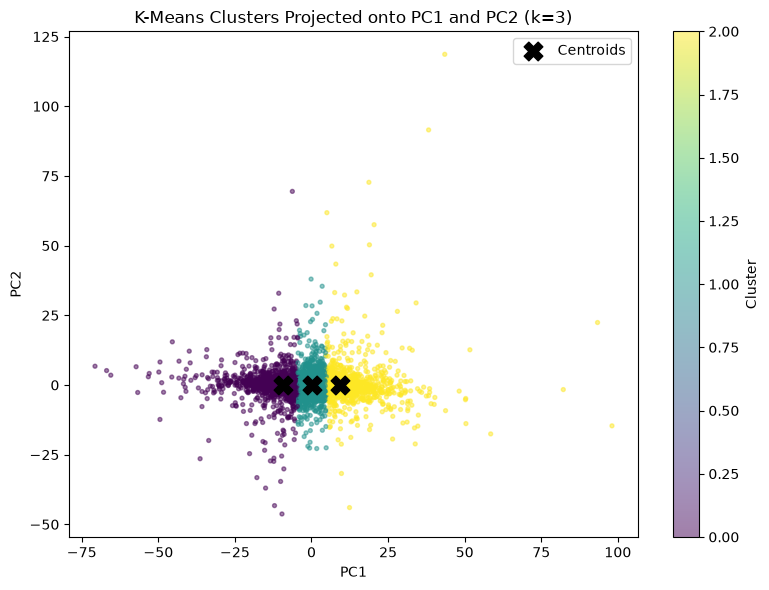

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(clustered_kmeans["PC1"], clustered_kmeans["PC2"], c=clustered_kmeans["cluster"], cmap="viridis", s=8, alpha=0.5)
centers = kmeans.cluster_centers_
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=180, color="black", label="Centroids")
ax.set(xlabel="PC1", ylabel="PC2", title=f"K-Means Clusters Projected onto PC1 and PC2 (k={chosen_k})")
fig.colorbar(points, ax=ax, label="Cluster")
ax.legend()
plt.tight_layout(); plt.show()

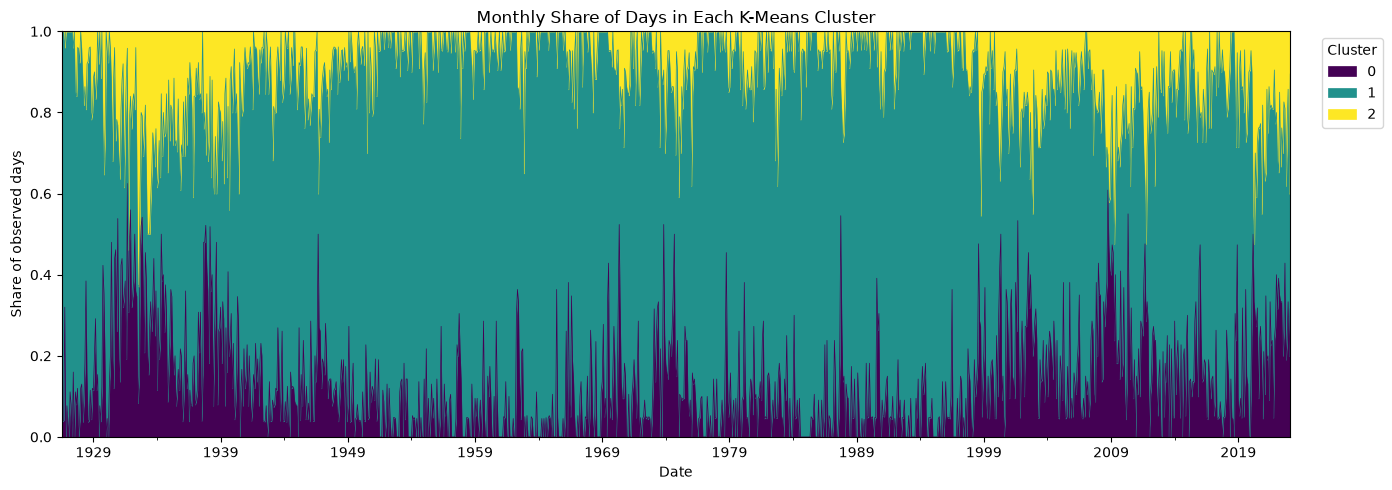

In [17]:
monthly_share = pd.crosstab(clustered_kmeans.index.to_period("M"), clustered_kmeans["cluster"], normalize="index").reindex(columns=range(chosen_k), fill_value=0)

monthly_share.index = monthly_share.index.to_timestamp()
ax = monthly_share.plot.area(figsize=(14, 5), colormap="viridis", linewidth=0.5)
ax.set(xlabel="Date", ylabel="Share of observed days", title="Monthly Share of Days in Each K-Means Cluster", ylim=(0, 1))
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

State changes: 32
row_0
1926-07    0
1926-11    1
1927-12    0
1929-09    1
1933-04    0
1937-06    1
1938-07    0
1945-03    1
1945-11    0
1948-12    1
1949-11    0
1953-08    1
1954-06    0
1957-09    1
1958-05    0
1960-05    1
1961-03    0
1970-01    1
1970-12    0
1973-12    1
1975-04    0
1980-02    1
1980-08    0
1981-08    1
1982-12    0
1990-08    1
1991-04    0
2001-04    1
2001-12    0
2008-01    1
2009-07    0
2020-03    1
2020-05    0
Freq: M, Name: USREC, dtype: int64
[('1926-11', '1927-12'), ('1929-09', '1933-04'), ('1937-06', '1938-07'), ('1945-03', '1945-11'), ('1948-12', '1949-11'), ('1953-08', '1954-06'), ('1957-09', '1958-05'), ('1960-05', '1961-03'), ('1970-01', '1970-12'), ('1973-12', '1975-04'), ('1980-02', '1980-08'), ('1981-08', '1982-12'), ('1990-08', '1991-04'), ('2001-04', '2001-12'), ('2008-01', '2009-07'), ('2020-03', '2020-05')]


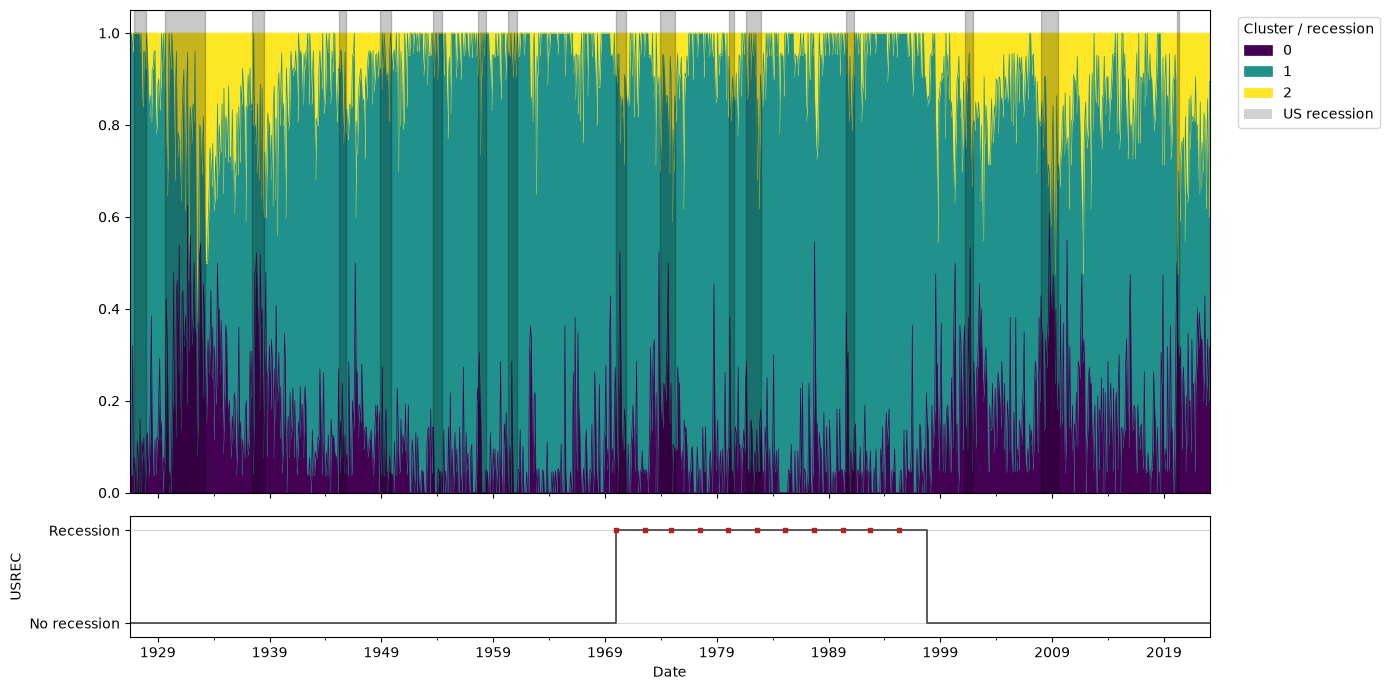

In [22]:
cluster_months = monthly_share.copy()
cluster_months.index = cluster_months.index.to_period("M")

usrec = pd.read_csv("HW5USREC.csv", parse_dates=["observation_date"])
usrec["month"] = usrec["observation_date"].dt.to_period("M")
rec_by_month = usrec.set_index("month")["USREC"].reindex(cluster_months.index).sort_index().astype(int)
changes = rec_by_month.ne(rec_by_month.shift())
print("State changes:", int(changes.iloc[1:].sum()))
cluster_months.index = cluster_months.index.to_timestamp()

recession = rec_by_month.eq(1)
starts = recession & ~recession.shift(1, fill_value=False)
ends = recession & ~recession.shift(-1, fill_value=False)


dates = rec_by_month.index.to_timestamp()

# Keep only the months present in both datasets
if rec_by_month.isna().any():
    raise ValueError("USREC is missing one or more portfolio months.")

# Plot cluster composition above recession periods
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={"height_ratios": [4, 1]})

cluster_months.plot.area(ax=ax1, colormap="viridis", linewidth=0.5)
for start, end in zip(rec_by_month.index[starts], rec_by_month.index[ends]):
    ax1.axvspan(
        start.to_timestamp(),
        (end + 1).to_timestamp(),
        color="black",
        alpha=0.22,
        zorder=10
    )
month_starts = rec_by_month.index.to_timestamp()
rec_vals = rec_by_month.to_numpy(dtype=int)
month_edges = month_starts.append(
    pd.DatetimeIndex([(rec_by_month.index[-1] + 1).to_timestamp()])
)
step_values = np.append(rec_vals, rec_vals[-1])
ax2.step(month_edges, step_values, where="post", color="0.25", linewidth=1.2)
ax2.scatter(
    month_starts[rec_vals == 1],
    np.ones((rec_vals == 1).sum()),
    color="firebrick",
    s=8,
    marker="s",
    zorder=3,
)

ax2.set_ylim(-0.15, 1.15)
ax2.set_yticks([0, 1], labels=["No recession", "Recession"])
ax2.set_ylabel("USREC")
ax2.set_xlabel("Date")
ax2.grid(axis="y", alpha=0.5)
# Add a legend key for the shaded regions alongside the cluster keys.
handles, labels = ax1.get_legend_handles_labels()
handles.append(Patch(facecolor="black", alpha=0.18))
labels.append("US recession")
ax1.legend(handles, labels, title="Cluster / recession",
           bbox_to_anchor=(1.02, 1), loc="upper left")
print(rec_by_month[rec_by_month.ne(rec_by_month.shift())])
print(list(zip(
    rec_by_month.index[starts].astype(str),
    (rec_by_month.index[ends] + 1).astype(str)
)))
plt.tight_layout(); plt.show()